# Standalone global H1-H12 Extra Trees training

This Colab notebook needs only `horizon_training_dataset.csv`. It performs the same chronological splitting, preprocessing, validation, refitting, testing, metrics, and artifact saving flow as the XGBoost notebook. Extra Trees trains on CPU.

In [1]:
%pip install -q pandas scikit-learn==1.6.1 joblib==1.6.0 matplotlib seaborn

## Mount Drive and configure paths

Upload the training CSV to `MyDrive/demand-forecasting/Dataset/horizon_training_dataset.csv`. Artifacts are first saved under `/content/etr_artifacts` and then copied to Drive.

In [2]:
import json
import platform
import shutil
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from google.colab import drive

drive.mount("/content/drive")

DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/demand-forecasting")
DRIVE_DATA_FILE = DRIVE_PROJECT_DIR / "Dataset" / "horizon_training_dataset.csv"
DRIVE_ARTIFACT_DIR = DRIVE_PROJECT_DIR / "artifacts"
LOCAL_ARTIFACT_DIR = Path("/content/etr_artifacts")

if not DRIVE_DATA_FILE.exists():
    raise FileNotFoundError(f"Upload horizon_training_dataset.csv to: {DRIVE_DATA_FILE}")

print(f"Dataset: {DRIVE_DATA_FILE}")
print(f"Local output: {LOCAL_ARTIFACT_DIR}")
print(f"Drive output: {DRIVE_ARTIFACT_DIR}")

Mounted at /content/drive
Dataset: /content/drive/MyDrive/demand-forecasting/Dataset/horizon_training_dataset.csv
Local output: /content/etr_artifacts
Drive output: /content/drive/MyDrive/demand-forecasting/artifacts


## Load data and create chronological splits

The final three target months are the test set, the preceding three target months are validation, and all earlier target months are training.

In [3]:
TARGET_COLUMN = "future_demand_kg"
CATEGORICAL_FEATURES = ["crop", "location", "origin_season", "target_season"]
EXCLUDED_FEATURES = ["forecast_origin_month", "target_month", TARGET_COLUMN]
VALIDATION_MONTHS = 3
TEST_MONTHS = 3

data = pd.read_csv(DRIVE_DATA_FILE, parse_dates=["forecast_origin_month", "target_month"])
required = ["forecast_origin_month", "target_month", "forecast_horizon", *CATEGORICAL_FEATURES, TARGET_COLUMN]
missing = [column for column in required if column not in data.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")
if data[TARGET_COLUMN].isna().any():
    raise ValueError("Training data contains missing future targets.")

data = data.sort_values(["target_month", "forecast_origin_month"]).reset_index(drop=True)
final_month = data["target_month"].max().to_period("M").to_timestamp()
test_start = final_month - pd.DateOffset(months=TEST_MONTHS - 1)
validation_start = test_start - pd.DateOffset(months=VALIDATION_MONTHS)
train = data[data["target_month"] < validation_start].copy()
validation = data[data["target_month"].between(validation_start, test_start - pd.DateOffset(months=1))].copy()
test = data[data["target_month"] >= test_start].copy()

for name, split in {"train": train, "validation": validation, "test": test}.items():
    if split.empty:
        raise ValueError(f"{name} split is empty.")
    if set(split["forecast_horizon"].unique()) != set(range(1, 13)):
        raise ValueError(f"{name} split does not contain every H1-H12 horizon.")
if not (train["target_month"].max() < validation["target_month"].min() < test["target_month"].min()):
    raise ValueError("Chronological split boundaries overlap.")

print(f"Train: {len(train):,} rows, {train.target_month.min().date()} to {train.target_month.max().date()}")
print(f"Validation: {len(validation):,} rows, {validation.target_month.min().date()} to {validation.target_month.max().date()}")
print(f"Test: {len(test):,} rows, {test.target_month.min().date()} to {test.target_month.max().date()}")

Train: 6,210 rows, 2024-02-01 to 2025-06-01
Validation: 1,620 rows, 2025-07-01 to 2025-09-01
Test: 1,620 rows, 2025-10-01 to 2025-12-01


## Define preprocessing and Extra Trees

Categorical values are one-hot encoded inside the saved pipeline. Numeric missing values use training medians, and categorical missing values use the most frequent training value.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

FEATURE_COLUMNS = [column for column in data.columns if column not in EXCLUDED_FEATURES]
NUMERIC_FEATURES = [column for column in FEATURE_COLUMNS if column not in CATEGORICAL_FEATURES]
unexpected_text = [column for column in NUMERIC_FEATURES if not pd.api.types.is_numeric_dtype(data[column])]
if unexpected_text:
    raise ValueError(f"Features need an encoding policy: {unexpected_text}")

ETR_PARAMS = {
    "n_estimators": 500, "criterion": "squared_error", "max_depth": None,
    "min_samples_split": 2, "min_samples_leaf": 2, "max_features": 0.8,
    "bootstrap": False, "random_state": 42, "n_jobs": -1,
}

def build_pipeline():
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    preprocessor = ColumnTransformer(
        [("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
         ("numeric", numeric_pipeline, NUMERIC_FEATURES)],
        remainder="drop", verbose_feature_names_out=False,
    )
    return Pipeline([("preprocessor", preprocessor), ("model", ExtraTreesRegressor(**ETR_PARAMS))])

def split_xy(frame):
    return frame[FEATURE_COLUMNS].copy(), frame[TARGET_COLUMN].copy()

print(f"Features: {len(FEATURE_COLUMNS)} ({len(CATEGORICAL_FEATURES)} categorical, {len(NUMERIC_FEATURES)} numeric)")

Features: 52 (4 categorical, 48 numeric)


## Train, validate, refit, and test

The validation pipeline is fitted on training data only. A separate final pipeline is then fitted on train plus validation and evaluated once on the untouched test set.

In [5]:
X_train, y_train = split_xy(train)
X_validation, y_validation = split_xy(validation)
X_test, y_test = split_xy(test)

validation_pipeline = build_pipeline()
validation_pipeline.fit(X_train, y_train)
validation_values = validation_pipeline.predict(X_validation)

train_validation = pd.concat([train, validation], ignore_index=True).sort_values("target_month")
X_train_validation, y_train_validation = split_xy(train_validation)
final_pipeline = build_pipeline()
final_pipeline.fit(X_train_validation, y_train_validation)
test_values = final_pipeline.predict(X_test)
print("Training complete.")

Training complete.


## Evaluate overall and by horizon

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def prediction_table(source, values, split_name):
    output = source[["forecast_origin_month", "target_month", "crop", "location", "forecast_horizon", TARGET_COLUMN]].copy()
    output["etr_prediction"] = values
    output["split"] = split_name
    output["absolute_error"] = (output[TARGET_COLUMN] - output["etr_prediction"]).abs()
    return output

def metric_values(actual, predicted):
    denominator = np.abs(actual).sum()
    return {"mae": mean_absolute_error(actual, predicted),
            "rmse": np.sqrt(mean_squared_error(actual, predicted)),
            "wape": np.abs(actual - predicted).sum() / denominator if denominator > 0 else np.nan,
            "r2": r2_score(actual, predicted)}

validation_predictions = prediction_table(validation, validation_values, "validation")
test_predictions = prediction_table(test, test_values, "test")
records = []
for split_name, predictions in [("validation", validation_predictions), ("test", test_predictions)]:
    records.append({"model": "extra_trees", "split": split_name, "forecast_horizon": "overall", "rows": len(predictions), **metric_values(predictions[TARGET_COLUMN], predictions["etr_prediction"])})
    for horizon, group in predictions.groupby("forecast_horizon"):
        records.append({"model": "extra_trees", "split": split_name, "forecast_horizon": int(horizon), "rows": len(group), **metric_values(group[TARGET_COLUMN], group["etr_prediction"])})
metrics = pd.DataFrame(records)
display(metrics)

,model,split,forecast_horizon,rows,mae,rmse,wape,r2
0,extra_trees,validation,overall,1620,548.967316,708.553665,0.205477,0.557060
1,extra_trees,validation,1,135,544.961870,709.329377,0.203978,0.556090
2,extra_trees,validation,2,135,540.978346,706.428087,0.202487,0.559714
3,extra_trees,validation,3,135,541.264065,702.596330,0.202594,0.564477
4,extra_trees,validation,4,135,548.272574,709.318518,0.205217,0.556103
5,extra_trees,validation,5,135,552.093575,712.767343,0.206647,0.551776
6,extra_trees,validation,6,135,551.813119,710.152355,0.206542,0.555059
7,extra_trees,validation,7,135,552.207911,710.259191,0.206690,0.554925
8,extra_trees,validation,8,135,550.875060,709.023818,0.206191,0.556472
9,extra_trees,validation,9,135,550.021737,703.467602,0.205872,0.563396


## Save locally and to Google Drive

In [7]:
local_model_dir = LOCAL_ARTIFACT_DIR / "models"
local_prediction_dir = LOCAL_ARTIFACT_DIR / "predictions"
local_report_dir = LOCAL_ARTIFACT_DIR / "reports"
drive_model_dir = DRIVE_ARTIFACT_DIR / "models"
drive_prediction_dir = DRIVE_ARTIFACT_DIR / "predictions"
drive_report_dir = DRIVE_ARTIFACT_DIR / "reports"
for directory in [local_model_dir, local_prediction_dir, local_report_dir, drive_model_dir, drive_prediction_dir, drive_report_dir]:
    directory.mkdir(parents=True, exist_ok=True)

files = {
    local_model_dir / "global_etr_pipeline.joblib": ("model", final_pipeline),
    local_prediction_dir / "etr_validation_predictions.csv": ("csv", validation_predictions),
    local_prediction_dir / "etr_test_predictions.csv": ("csv", test_predictions),
    local_report_dir / "etr_metrics.csv": ("csv", metrics),
}
for path, (kind, value) in files.items():
    joblib.dump(value, path) if kind == "model" else value.to_csv(path, index=False)

metadata = {
    "model": "global_direct_multi_horizon_extra_trees", "target": TARGET_COLUMN,
    "feature_columns": FEATURE_COLUMNS, "categorical_features": CATEGORICAL_FEATURES,
    "extra_trees_parameters": ETR_PARAMS, "final_fit_data": "train + validation",
    "validation_prediction_model": "train only", "test_prediction_model": "train + validation",
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "joblib": joblib.__version__},
}
metadata_file = local_report_dir / "etr_training_metadata.json"
metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

destination_map = {
    local_model_dir / "global_etr_pipeline.joblib": drive_model_dir / "global_etr_pipeline.joblib",
    local_prediction_dir / "etr_validation_predictions.csv": drive_prediction_dir / "etr_validation_predictions.csv",
    local_prediction_dir / "etr_test_predictions.csv": drive_prediction_dir / "etr_test_predictions.csv",
    local_report_dir / "etr_metrics.csv": drive_report_dir / "etr_metrics.csv",
    metadata_file: drive_report_dir / "etr_training_metadata.json",
}
for source, destination in destination_map.items():
    shutil.copy2(source, destination)

print("Saved artifacts:")
for destination in destination_map.values():
    print(destination)

Saved artifacts:
/content/drive/MyDrive/demand-forecasting/artifacts/models/global_etr_pipeline.joblib
/content/drive/MyDrive/demand-forecasting/artifacts/predictions/etr_validation_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/predictions/etr_test_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/reports/etr_metrics.csv
/content/drive/MyDrive/demand-forecasting/artifacts/reports/etr_training_metadata.json


## Visualize model results

These are the same three diagnostic graphs used in the XGBoost notebook, generated from the Extra Trees predictions.

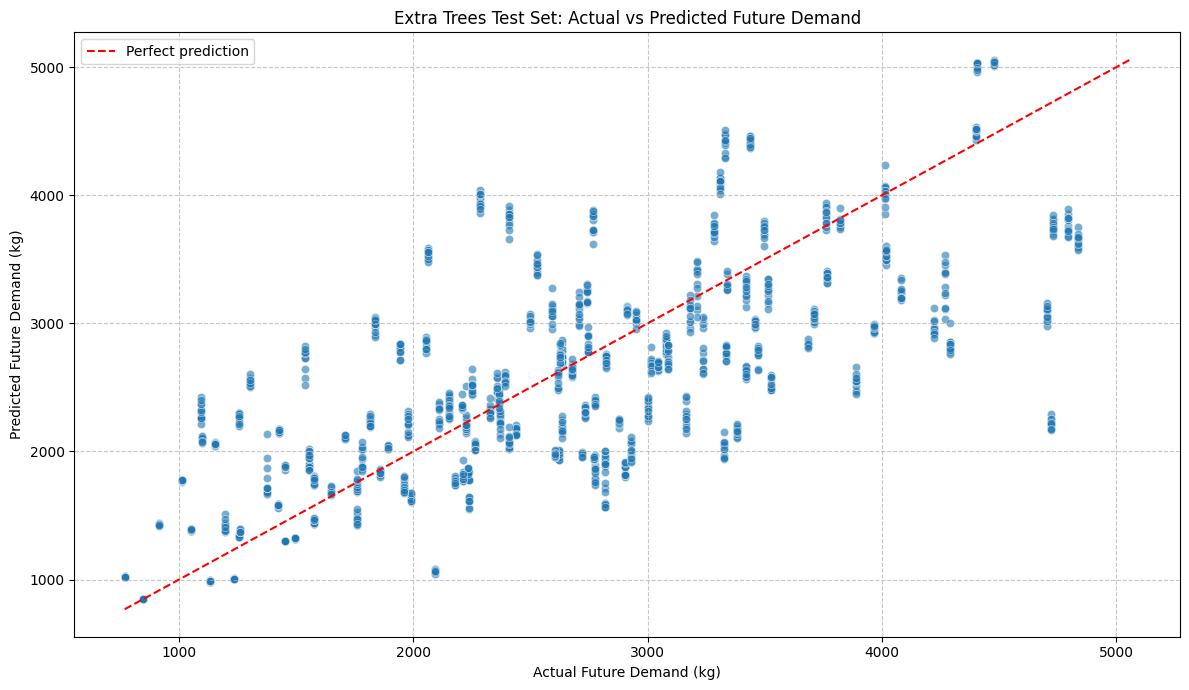

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: actual versus predicted demand on the untouched test set
minimum = min(test_predictions[TARGET_COLUMN].min(), test_predictions["etr_prediction"].min())
maximum = max(test_predictions[TARGET_COLUMN].max(), test_predictions["etr_prediction"].max())
plt.figure(figsize=(12, 7))
sns.scatterplot(data=test_predictions, x=TARGET_COLUMN, y="etr_prediction", alpha=0.6)
plt.plot([minimum, maximum], [minimum, maximum], "r--", label="Perfect prediction")
plt.title("Extra Trees Test Set: Actual vs Predicted Future Demand")
plt.xlabel("Actual Future Demand (kg)")
plt.ylabel("Predicted Future Demand (kg)")
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()

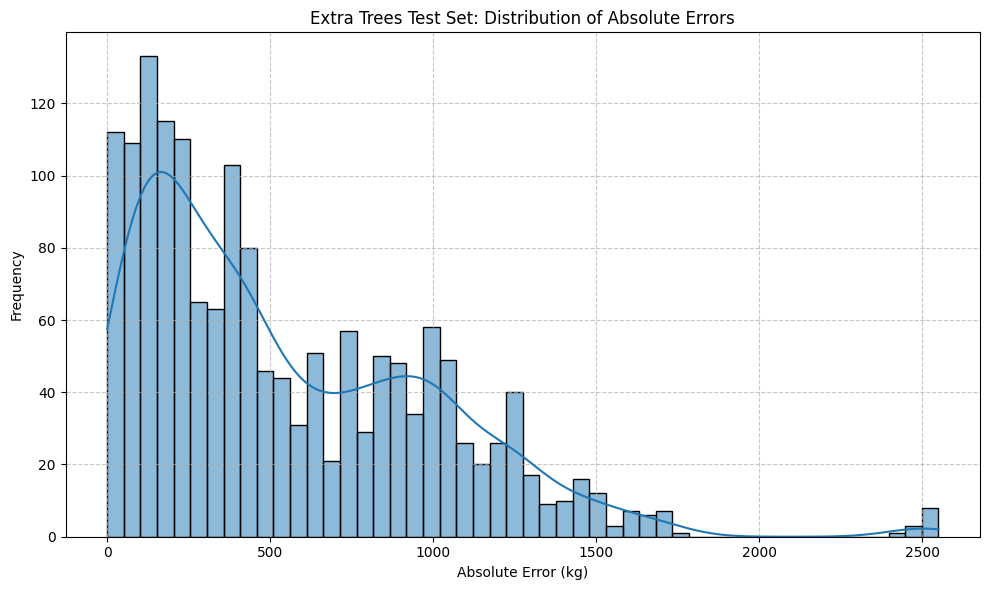

In [9]:
# Plot 2: distribution of absolute test errors
plt.figure(figsize=(10, 6))
sns.histplot(test_predictions["absolute_error"], bins=50, kde=True)
plt.title("Extra Trees Test Set: Distribution of Absolute Errors")
plt.xlabel("Absolute Error (kg)")
plt.ylabel("Frequency")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

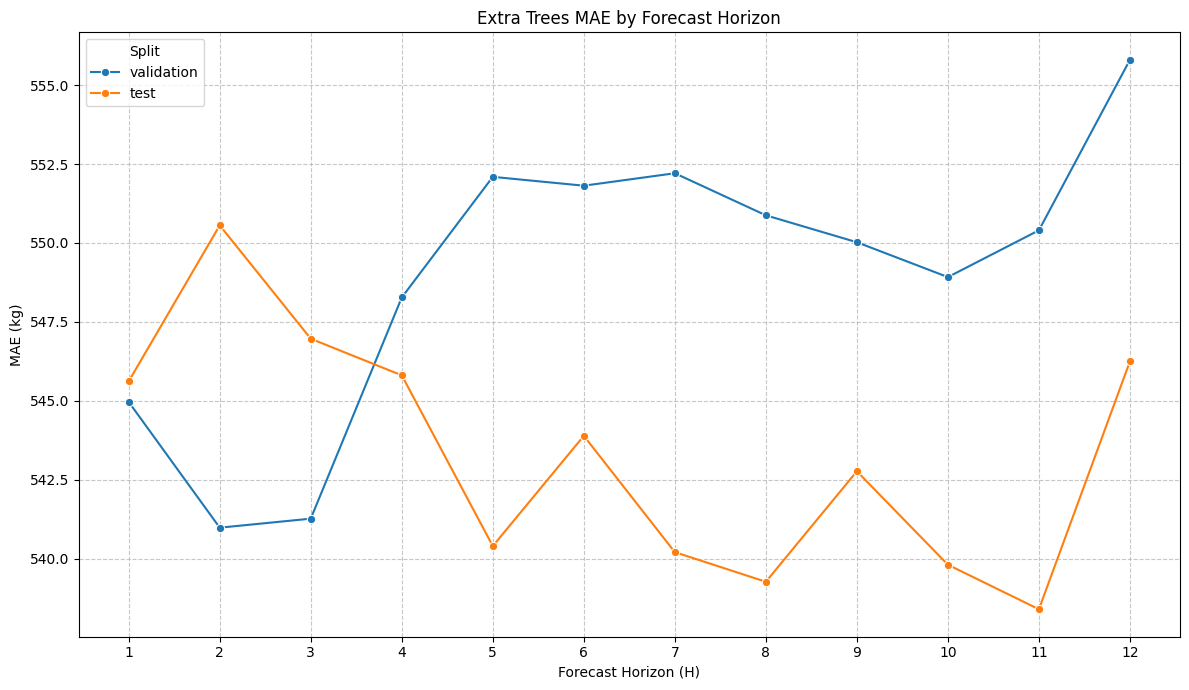

In [10]:
# Plot 3: MAE by forecast horizon for validation and test sets
metrics_by_horizon = metrics[metrics["forecast_horizon"] != "overall"].copy()
metrics_by_horizon["forecast_horizon"] = metrics_by_horizon["forecast_horizon"].astype(int)
plt.figure(figsize=(12, 7))
sns.lineplot(data=metrics_by_horizon, x="forecast_horizon", y="mae", hue="split", marker="o")
plt.title("Extra Trees MAE by Forecast Horizon")
plt.xlabel("Forecast Horizon (H)")
plt.ylabel("MAE (kg)")
plt.xticks(range(1, 13))
plt.grid(True, linestyle="--", alpha=0.7)
plt.legend(title="Split")
plt.tight_layout()
plt.show()